<a href="https://colab.research.google.com/github/SujahathMSM/Building-LLMs-From-Scratch/blob/main/LLM_From_Scratch_Complete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/SujahathMSM/Pytorch-DeepLearning/blob/main/LLM_From_Scratch_Complete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Building an LLM from scratch: from tensors to model input

This notebook combines all the notebooks in this repo into one path, in the order you'd actually build an LLM.

An LLM can't read text. It only works with numbers. Everything here is about one job: **turning raw text into the numbers an LLM can learn from.**

| Part | What you do | Original notebook |
|---|---|---|
| 1. PyTorch basics | Learn tensors, the "boxes of numbers" everything runs on | `001_Pytorch_Fundamentals` |
| 2. Tokenizing text | Split text into pieces and give each piece an ID | `Tokenizer` |
| 3. Byte pair encoding | Use GPT-2's real tokenizer, which never fails on new words | `BytePairEncoding(BPE)` |
| 4. Token embeddings | Turn each ID into a vector that carries meaning | `TokenEmbedding` |
| 5. Sliding window | Cut the text into input → target training pairs | `DataSamplingWithASlidingWindow` |
| 6. Positional embeddings | Add word order, giving the final input to the model | `BuildingLLMsFromScratch` |

The full pipeline:

```
raw text → tokens → token IDs → (input, target) pairs → token embeddings + position embeddings → model
```

## Setup

Install `tiktoken` and download the short story used as training text (*The Verdict* by Edith Wharton, which is in the public domain). The download only runs if the file isn't there yet, so this works both in Colab and locally.

In [125]:
!pip install -q tiktoken

In [126]:
import os
import urllib.request

file_path = "the-verdict.txt"
if not os.path.exists(file_path):
    url = ("https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/"
           "main/ch02/01_main-chapter-code/the-verdict.txt")
    urllib.request.urlretrieve(url, file_path)

with open(file_path, "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Total number of characters:", len(raw_text))
print(raw_text[:99])

Total number of characters: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


---
# Part 1: PyTorch basics (tensors)

A **tensor** is a box of numbers. The number of dimensions (`ndim`) tells you how many indexes you need to reach a single number:

- **Scalar**: one number, `ndim = 0`
- **Vector**: a list of numbers, `ndim = 1`
- **Matrix**: a table of numbers, `ndim = 2`
- **Tensor**: 3 or more dimensions

In an LLM, a batch of embedded text is a 3D tensor with shape `[batch, tokens, embedding_size]`. You'll see exactly that shape in Part 6.

In [127]:
# Shows your GPU, if you have one. In Colab: Runtime > Change runtime type > GPU
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [128]:
import torch
print(torch.__version__)

2.14.1+cpu


### Scalar

In [129]:
#scaler
scaler = torch.tensor(9)
scaler

tensor(9)

In [130]:
scaler.item()

9

In [131]:
scaler.ndim

0

### Vector

In [132]:
#Vector
vector = torch.tensor([1,2,3,4])
vector

tensor([1, 2, 3, 4])

In [133]:
vector.ndim

1

In [134]:
vector.shape

torch.Size([4])

### Matrix

In [135]:
# MATRIX
MATRIX = torch.tensor([[7,8],
                       [9, 10]])
MATRIX

tensor([[ 7,  8],
        [ 9, 10]])

In [136]:
MATRIX.ndim

2

In [137]:
MATRIX.shape

torch.Size([2, 2])

### Tensor (3D)

In [138]:
#TENSOR

TENSOR = torch.tensor([[[1,2,3],
                        [4,5,6],
                        [7,8,9]]])
TENSOR

tensor([[[1, 2, 3],
         [4, 5, 6],
         [7, 8, 9]]])

In [139]:
TENSOR.ndim

3

In [140]:
TENSOR.shape

torch.Size([1, 3, 3])

---
# Part 2: Tokenizing text

**Goal:** split text into small pieces (tokens), then give each unique token an integer ID.

```
"Hello, world." → ["Hello", ",", "world", "."] → [12, 3, 45, 7]
```

This part builds a simple tokenizer by hand using regular expressions.

### Splitting text with regex

In [141]:
import re
text = "Hello, world. This, is a test."
result = re.split(r'(\s)', text)
print(result)

['Hello,', ' ', 'world.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


In [142]:
result = re.split(r'([,.]|\s)', text)
print(result)

['Hello', ',', '', ' ', 'world', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


In [143]:
result = [item for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'This', ',', 'is', 'a', 'test', '.']


### Tokenizing the whole story

The same regex split, now applied to the full text. It splits on punctuation, `--`, and whitespace, then removes empty strings.

In [144]:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(preprocessed[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


In [145]:
print(len(preprocessed))

4690


### Building a vocabulary

The vocabulary maps every unique token to an integer: `token → ID`.

In [146]:
all_words =sorted(set(preprocessed))
print(all_words)

['!', '"', "'", '(', ')', ',', '--', '.', ':', ';', '?', 'A', 'Ah', 'Among', 'And', 'Are', 'Arrt', 'As', 'At', 'Be', 'Begin', 'Burlington', 'But', 'By', 'Carlo', 'Chicago', 'Claude', 'Come', 'Croft', 'Destroyed', 'Devonshire', 'Don', 'Dubarry', 'Emperors', 'Florence', 'For', 'Gallery', 'Gideon', 'Gisburn', 'Gisburns', 'Grafton', 'Greek', 'Grindle', 'Grindles', 'HAD', 'Had', 'Hang', 'Has', 'He', 'Her', 'Hermia', 'His', 'How', 'I', 'If', 'In', 'It', 'Jack', 'Jove', 'Just', 'Lord', 'Made', 'Miss', 'Money', 'Monte', 'Moon-dancers', 'Mr', 'Mrs', 'My', 'Never', 'No', 'Now', 'Nutley', 'Of', 'Oh', 'On', 'Once', 'Only', 'Or', 'Perhaps', 'Poor', 'Professional', 'Renaissance', 'Rickham', 'Riviera', 'Rome', 'Russian', 'Sevres', 'She', 'Stroud', 'Strouds', 'Suddenly', 'That', 'The', 'Then', 'There', 'They', 'This', 'Those', 'Though', 'Thwing', 'Thwings', 'To', 'Usually', 'Venetian', 'Victor', 'Was', 'We', 'Well', 'What', 'When', 'Why', 'Yes', 'You', '_', 'a', 'abdication', 'able', 'about', 'above',

In [147]:
vocab = {token:integer for integer, token in enumerate(all_words)}
for i, item in enumerate(vocab.items()):
  print(item)
  if (i >= 50):
    break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


### SimpleTokenizerV1

- `encode`: text → IDs
- `decode`: IDs → text

In [148]:
import re

class SimpleTokenizerV1:
    def __init__(self, vocab):
        # Store token -> id mapping inside the object
        self.str_to_int = vocab

        # Create reverse mapping: id -> token
        self.int_to_str = {i: s for s, i in vocab.items()}

    def encode(self, text):
        # Split text into tokens (words, punctuation, whitespace)
        preprocessed = re.split(r'([,.?!"()\']|--|\s)', text)

        # Remove empty strings and extra spaces
        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]

        # Convert tokens to integer IDs using the vocab
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        # Convert IDs back to tokens and join with spaces
        text = " ".join([self.int_to_str[i] for i in ids])

        # Remove spaces before punctuation
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

In [149]:
tokenizer = SimpleTokenizerV1(vocab)

text = """It's the last he painted, you know,"
Mrs. Gisburn said with pardonable pride."""

ids = tokenizer.encode(text)
print(ids)

[56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [150]:
print(tokenizer.decode(ids))

It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.


### The problem with V1

If a word isn't in the vocabulary, V1 crashes. "Hello" never appears in the story:

In [151]:
try:
    tokenizer.encode("Hello, do you like tea?")
except KeyError as e:
    print("KeyError: unknown token", e)

KeyError: unknown token 'Hello'


### Adding special tokens

Two special tokens fix this:

- `<|unk|>`: replaces any unknown word
- `<|endoftext|>`: marks the boundary between two separate texts

In [152]:
all_tokens = sorted(list(set(preprocessed)))
print(all_tokens)

['!', '"', "'", '(', ')', ',', '--', '.', ':', ';', '?', 'A', 'Ah', 'Among', 'And', 'Are', 'Arrt', 'As', 'At', 'Be', 'Begin', 'Burlington', 'But', 'By', 'Carlo', 'Chicago', 'Claude', 'Come', 'Croft', 'Destroyed', 'Devonshire', 'Don', 'Dubarry', 'Emperors', 'Florence', 'For', 'Gallery', 'Gideon', 'Gisburn', 'Gisburns', 'Grafton', 'Greek', 'Grindle', 'Grindles', 'HAD', 'Had', 'Hang', 'Has', 'He', 'Her', 'Hermia', 'His', 'How', 'I', 'If', 'In', 'It', 'Jack', 'Jove', 'Just', 'Lord', 'Made', 'Miss', 'Money', 'Monte', 'Moon-dancers', 'Mr', 'Mrs', 'My', 'Never', 'No', 'Now', 'Nutley', 'Of', 'Oh', 'On', 'Once', 'Only', 'Or', 'Perhaps', 'Poor', 'Professional', 'Renaissance', 'Rickham', 'Riviera', 'Rome', 'Russian', 'Sevres', 'She', 'Stroud', 'Strouds', 'Suddenly', 'That', 'The', 'Then', 'There', 'They', 'This', 'Those', 'Though', 'Thwing', 'Thwings', 'To', 'Usually', 'Venetian', 'Victor', 'Was', 'We', 'Well', 'What', 'When', 'Why', 'Yes', 'You', '_', 'a', 'abdication', 'able', 'about', 'above',

In [153]:
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token:integer for integer, token in enumerate(all_tokens)}
print(len(vocab.items()))

1132


In [154]:
for i, item in enumerate(list(vocab.items())[-5:]):
  print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


### SimpleTokenizerV2

This is the same as V1, except unknown words become `<|unk|>` instead of crashing.

In [155]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i: s for s, i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?!"()\']|--|\s)', text)

        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]

        # NEW PART (difference from V1)
        preprocessed = [
            item if item in self.str_to_int else "<|unk|>"
            for item in preprocessed
        ]

        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.:;?!"()\'])', r'\1', text)
        return text

In [156]:
tokenizer = SimpleTokenizerV2(vocab)

text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
text = " <|endoftext|> ".join((text1, text2))
print(text)

ids = tokenizer.encode(text)
print(ids)
print(tokenizer.decode(ids))

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.
[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]
<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.


Notice "Hello" and "palace" come back as `<|unk|>`, so their meaning is lost. Byte pair encoding (BPE) fixes this.

---
# Part 3: Byte pair encoding (BPE), GPT-2's real tokenizer

Instead of whole words, BPE uses **subword pieces**. If a word is unknown, it's split into smaller known pieces, down to single characters if needed. So:

- There's no `<|unk|>` and no information is lost.
- The vocabulary is 50,257 tokens for GPT-2.

We use OpenAI's `tiktoken` library rather than building BPE by hand.

In [157]:
from importlib.metadata import version
import tiktoken
print("tiktoken version:", version("tiktoken"))

tiktoken version: 0.14.0


In [158]:
tokenizer = tiktoken.get_encoding('gpt2')

In [159]:
text = (
    "Hello, do you like tea <|endoftext|> In the sunlight terraces "
    "of someUnknownPlace"
)

In [160]:
integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[15496, 11, 466, 345, 588, 8887, 220, 50256, 554, 262, 19606, 8812, 2114, 286, 617, 20035, 27271]


In [161]:
strings = tokenizer.decode(integers)
print(strings)

Hello, do you like tea <|endoftext|> In the sunlight terraces of someUnknownPlace


### How BPE handles a made-up word

`"Akwirw ier"` isn't a real word, but BPE still encodes it by breaking it into pieces. Decode each ID on its own to see the pieces:

In [162]:
new_word = "Akwirw ier"
int_tokens = tokenizer.encode(new_word)
print(int_tokens)

[33901, 86, 343, 86, 220, 959]


In [163]:
print(tokenizer.decode(int_tokens))

Akwirw ier


In [164]:
print(tokenizer.decode([33901]))

Ak


In [165]:
print(tokenizer.decode([86]))

w


In [166]:
print(tokenizer.decode([343]))

ir


In [167]:
print(tokenizer.decode([220]))

In [168]:
print(tokenizer.decode([959]))

ier


In [169]:
text = (
    "Hello, do you like tea <|endoftext|> In the sunlight terraces"
    "of some randomWordFromMyself Sujahath"
)

intsss = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(intsss)

[15496, 11, 466, 345, 588, 8887, 220, 50256, 554, 262, 19606, 8812, 2114, 1659, 617, 4738, 26449, 4863, 3666, 944, 1778, 31558, 776]


---
# Part 4: Token embeddings

A token ID like `3626` is just a label, so the number itself means nothing. An **embedding** turns each ID into a vector (a list of numbers) where **similar meanings end up close together**.

### 4a. Intuition: pretrained word2vec

Before building our own, look at a trained embedding model (Google News word2vec, 300 numbers per word) to see what "meaning as vectors" looks like.

> ⚠️ This downloads about **1.6 GB**. You can skip to 4b if you just want to keep going; nothing later depends on 4a. The outputs below are from an earlier run.

In [170]:
!!pip install gensim

['Requirement already satisfied: gensim in /usr/local/lib/python3.13/dist-packages (4.4.0)',
 'Requirement already satisfied: numpy>=1.18.5 in /usr/local/lib/python3.13/dist-packages (from gensim) (2.4.6)',
 'Requirement already satisfied: scipy>=1.7.0 in /usr/local/lib/python3.13/dist-packages (from gensim) (1.16.3)',
 'Requirement already satisfied: smart_open>=1.8.1 in /usr/local/lib/python3.13/dist-packages (from gensim) (9.0.2)',
 'Requirement already satisfied: wrapt in /usr/local/lib/python3.13/dist-packages (from smart_open>=1.8.1->gensim) (2.5.2)']

In [171]:
import gensim.downloader as api
from gensim.models import KeyedVectors

In [172]:
print("Downloading model...")
wv = api.load('word2vec-google-news-300')
print("Model loaded successfully!")

Model loaded successfully!


In [173]:
print(wv['computer'])

[ 1.07421875e-01 -2.01171875e-01  1.23046875e-01  2.11914062e-01
 -9.13085938e-02  2.16796875e-01 -1.31835938e-01  8.30078125e-02
  2.02148438e-01  4.78515625e-02  3.66210938e-02 -2.45361328e-02
  2.39257812e-02 -1.60156250e-01 -2.61230469e-02  9.71679688e-02
 -6.34765625e-02  1.84570312e-01  1.70898438e-01 -1.63085938e-01
 -1.09375000e-01  1.49414062e-01 -4.65393066e-04  9.61914062e-02
  1.68945312e-01  2.60925293e-03  8.93554688e-02  6.49414062e-02
  3.56445312e-02 -6.93359375e-02 -1.46484375e-01 -1.21093750e-01
 -2.27539062e-01  2.45361328e-02 -1.24511719e-01 -3.18359375e-01
 -2.20703125e-01  1.30859375e-01  3.66210938e-02 -3.63769531e-02
 -1.13281250e-01  1.95312500e-01  9.76562500e-02  1.26953125e-01
  6.59179688e-02  6.93359375e-02  1.02539062e-02  1.75781250e-01
 -1.68945312e-01  1.21307373e-03 -2.98828125e-01 -1.15234375e-01
  5.66406250e-02 -1.77734375e-01 -2.08984375e-01  1.76757812e-01
  2.38037109e-02 -2.57812500e-01 -4.46777344e-02  1.88476562e-01
  5.51757812e-02  5.02929

In [174]:
similar_words = wv.most_similar('python')
print(f"Words most similar to 'python': {similar_words[:3]}")

Words most similar to 'python': [('pythons', 0.66883784532547), ('Burmese_python', 0.6680365800857544), ('snake', 0.6606292724609375)]


In [175]:
vector = wv['computer']
print(f"Vector shape for 'computer': {vector.shape}")

Vector shape for 'computer': (300,)


In [176]:
word = "banana"
if word in wv:
    print(f"{word} is in the vocabulary.")
else:
    print(f"{word} is not in the vocabulary.")

banana is in the vocabulary.


In [177]:
similarity = wv.similarity('woman', 'man')
print(f"Similarity between 'woman' and 'man': {similarity}")

Similarity between 'woman' and 'man': 0.7664012312889099


In [178]:
result = wv.most_similar(positive=['woman', 'king'], negative=['man'], topn=1)
print(f"Result of 'king' - 'man' + 'woman': {result[0]}")

Result of 'king' - 'man' + 'woman': ('queen', 0.7118193507194519)


In [179]:
similarity = wv.similarity('apple', 'banana')
print(f"Similarity between 'apple' and 'banana': {similarity}")

Similarity between 'apple' and 'banana': 0.5318406224250793


In [180]:
print(wv['Apple'])

[-1.74804688e-01  3.00292969e-02 -2.16796875e-01  1.56250000e-01
 -3.57421875e-01 -6.05468750e-02  1.36718750e-01  9.57031250e-02
  3.17382812e-03 -4.29687500e-02 -3.30078125e-01  2.57812500e-01
  2.51953125e-01 -2.77343750e-01 -6.98242188e-02 -2.95410156e-02
  3.22265625e-01 -7.76367188e-02 -3.06396484e-02 -1.67968750e-01
 -5.76171875e-02  3.05175781e-02  5.52368164e-03 -1.26953125e-01
 -1.44042969e-02  1.75781250e-01  9.47265625e-02  3.16406250e-01
 -7.81250000e-03 -3.40270996e-03  3.63769531e-02  1.11816406e-01
 -1.24023438e-01  1.29882812e-01 -3.22265625e-02 -1.60156250e-01
  7.56835938e-02  6.73828125e-02  4.08203125e-01  2.23632812e-01
  1.60156250e-01  3.63769531e-02 -1.64062500e-01 -3.51562500e-01
  4.49218750e-02  6.34765625e-02 -1.15234375e-01  3.12500000e-01
 -2.80761719e-02 -9.22851562e-02  5.98144531e-02  1.57470703e-02
 -1.15234375e-01  2.18750000e-01 -5.78613281e-02  2.07031250e-01
 -1.03515625e-01 -2.07031250e-01 -7.08007812e-02 -7.47070312e-02
  1.35742188e-01  1.80664

In [181]:
similarity = wv.similarity('Apple', 'apple')
print(f"Similarity between 'Apple' and 'apple': {similarity}")

Similarity between 'Apple' and 'apple': 0.3786771595478058


In [182]:
result = wv.most_similar(positive=['woman', 'king'], negative=['man'], topn=5)
print(f"Result of 'king' - 'man' + 'woman': {result}")

Result of 'king' - 'man' + 'woman': [('queen', 0.7118193507194519), ('monarch', 0.6189674139022827), ('princess', 0.5902431011199951), ('crown_prince', 0.5499460697174072), ('prince', 0.5377321839332581)]


In [183]:
result = wv.most_similar(positive=['RAM', 'Monitor', 'Keyboard'], negative=['Keyboard'], topn=5)
print(result)

[('By_JARED_JANES', 0.5405739545822144), ('By_VICTORIA_SHOULDIS', 0.538179874420166), ('By_JARED_TAYLOR', 0.5252323150634766), ('By_MADDIE_HANNA', 0.5242959856987), ('CPU_RAM', 0.5191538333892822)]


In [184]:
result = wv.most_similar(positive=['computer', 'mouse'], negative=['keyboard'], topn=5)
print(result)

[('computers', 0.5381786227226257), ('Computer', 0.4286578595638275), ('com_puter', 0.422382116317749), ('supercomputer', 0.4029233753681183), ('imagery_CGI', 0.39922839403152466)]


In [185]:
result = wv.most_similar(positive=['Rice', 'Curry', 'Chicken', 'vegetables'], negative=['banana'], topn=5)
print(result)

[('Lamb', 0.5187926888465881), ('Sausage_Gumbo', 0.5086236596107483), ('Spicy_Chicken', 0.5070229172706604), ('Cucumber_Salad', 0.4927563965320587), ('Tamale_Pie', 0.49156540632247925)]


In [186]:
result = wv.similar_by_word('Car', topn=5)
print(result)

[('car', 0.6677608489990234), ('Auto', 0.6563326716423035), ('Vehicle', 0.6293455362319946), ('Cars', 0.6291522979736328), ('##V_Midsize_Car', 0.621805727481842)]


In [187]:
result = wv.most_similar(positive=['Game', 'PC'], negative=['Keyboard'], topn=5)
print(result)

[('game', 0.4386070966720581), ('Thrones_Genesis', 0.4253532290458679), ('Game1', 0.42441362142562866), ('Tokyo_Masanori_Murakami', 0.407493531703949), ('PlayStation', 0.40423259139060974)]


### Cosine similarity

This measures how close two vectors point: 1 means the same direction, and 0 means unrelated. Related pairs (man/woman, nephew/niece) score high, and unrelated pairs (semiconductor/earthworm) score low.

In [188]:
import numpy as np

word1 = "man"
word2 = "woman"

word3 = "semiconductor"
word4 = "earthworm"

word5 = "nephew"
word6 = "niece"

#cosine similarity
def cosine_similarity(vec1, vec2):
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

v1 = wv[word1]
v2 = wv[word2]

v3 = wv[word3]
v4 = wv[word4]

v5 = wv[word5]
v6 = wv[word6]

cos_sim_1 = cosine_similarity(v1, v2)
cos_sim_2 = cosine_similarity(v3, v4)
cos_sim_3 = cosine_similarity(v5, v6)

print(f"Cosine similarity ({word1}, {word2}): {cos_sim_1:.4f}")
print(f"Cosine similarity ({word3}, {word4}): {cos_sim_2:.4f}")
print(f"Cosine similarity ({word5}, {word6}): {cos_sim_3:.4f}")

Cosine similarity (man, woman): 0.7664
Cosine similarity (semiconductor, earthworm): 0.0267
Cosine similarity (nephew, niece): 0.7594


### 4b. Building our own embedding layer in PyTorch

An LLM learns its own embeddings. `torch.nn.Embedding(vocab_size, output_dim)` is just a lookup table:

- one row per token ID
- each row is a vector of `output_dim` numbers
- the numbers start random and get adjusted during training, exactly like weights in any neural network

Looking up ID `3` returns row 3.

In [189]:
import torch

In [190]:
input_ids = torch.tensor([2, 3, 5,1])

In [191]:
vocab_size = 6
output_dim = 3

In [192]:
torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


In [193]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [194]:
print(embedding_layer(torch.tensor([2])))

tensor([[ 1.2753, -0.2010, -0.1606]], grad_fn=<EmbeddingBackward0>)


Pass several IDs at once and you get one row per ID:

In [195]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


---
# Part 5: Creating training data with a sliding window

An LLM is trained to do one thing: **predict the next token**. So training data is pairs of:

- **input**: a chunk of tokens
- **target**: the same chunk shifted one token to the right

```
input : [ I,    had,  always, thought ]
target: [ had,  always, thought, Jack ]
```

Each position in the input learns to predict the token at the same position in the target.

In [196]:
import tiktoken
tokenizer = tiktoken.get_encoding('gpt2')

In [197]:
enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

5145


In [198]:
enc_sample = enc_text[50:]

### Input vs target, side by side

Note: the target is `enc_sample[1:context_size+1]`. The original notebook had `[1:context_size]`, which made the target one token shorter than the input.

In [199]:
context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size + 1]
print(f"x: {x}")
print(f"y:      {y}")

x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


One chunk of 4 tokens actually holds 4 prediction tasks:

In [200]:
for i in range(1, context_size+1):
  context = enc_sample[:i]
  desired = enc_sample[i]
  print(context, "----->", desired)

[290] -----> 4920
[290, 4920] -----> 2241
[290, 4920, 2241] -----> 287
[290, 4920, 2241, 287] -----> 257


In [201]:
for i in range(1, context_size+1):
  context = enc_sample[:i]
  desired = enc_sample[i]
  print(tokenizer.decode(context), "----->", tokenizer.decode([desired]))

 and ----->  established
 and established ----->  himself
 and established himself ----->  in
 and established himself in ----->  a


### A PyTorch Dataset and DataLoader

- `GPTDatasetV1` slides a window of `max_length` tokens across the whole text. `stride` sets how far the window moves each time.
- `create_dataloader_v1` groups those windows into batches.

In [202]:
import tiktoken
import torch
from torch.utils.data import Dataset, DataLoader

# You need this class defined!
class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.tokenizer = tokenizer
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt)

        # Create sliding windows
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [203]:
def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )
    return dataloader

### `stride=1`: windows overlap heavily

Each batch moves the window by just one token:

In [204]:
dataloader = create_dataloader_v1(
    raw_text, batch_size=2, max_length=4, stride=4, shuffle=False
)

dataiter = iter(dataloader)
print("first batch ---", next(dataiter))
print("second batch ---", next(dataiter))
print("third batch ---", next(dataiter))

first batch --- [tensor([[  40,  367, 2885, 1464],
        [1807, 3619,  402,  271]]), tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899]])]
second batch --- [tensor([[10899,  2138,   257,  7026],
        [15632,   438,  2016,   257]]), tensor([[ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922]])]
third batch --- [tensor([[ 922, 5891, 1576,  438],
        [ 568,  340,  373,  645]]), tensor([[5891, 1576,  438,  568],
        [ 340,  373,  645, 1049]])]


### `stride=4`: no overlap, batches of 8

Setting `stride = max_length` means every token is used once, which reduces overfitting.

In [205]:
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=4, stride=4, shuffle=False
)

dataiter = iter(dataloader)
inputs, targets = next(dataiter)
print("Inputs\n", inputs)
print("\nTargets\n", targets)

Inputs
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


---
# Part 6: Token and positional embeddings, the final LLM input

Now we connect Parts 4 and 5: feed batches of token IDs into an embedding layer.

There's one more problem. The embedding for "cat" is the same whether it's the 1st or the 50th word. The model needs to know **word order**, so we add a second embedding: one vector per **position**.

```
final input = token embedding + position embedding
```

### Token embeddings

`vocab_size = 50257` is GPT-2's vocabulary size. (The original notebook had `50237`, a typo that would crash on any token ID of 50237 or higher.)

In [206]:
vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
token_embedding_layer.weight.shape

torch.Size([50257, 256])

In [207]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length, stride=max_length, shuffle=False
)
print(f"Total number of batches in the dataloader: {len(dataloader)}")

Total number of batches in the dataloader: 160


### Iterators: `next()` moves forward

Each `next()` gives the next batch. Calling `iter()` again starts over from the first batch.

In [208]:
data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs (first batch)\n", inputs)
print("Targets (first batch)\n", targets)

second_inputs, second_targets = next(data_iter)
print("\nInputs (second batch)\n", second_inputs)

Inputs (first batch)
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])
Targets (first batch)
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])

Inputs (second batch)
 tensor([[  287,   262,  6001,   286],
        [  465, 13476,    11,   339],
        [  550,  5710,   465, 12036],
        [   11,  6405,   257,  5527],
        [27075,    11,   290,  4920],
        [ 2241,   287,   257,  4489],
        [   64,   319,   262, 34686],
        [41976,    13,   357, 10915]])


### Embed the batch

The shape goes from `[8, 4]` (8 sequences × 4 token IDs) to `[8, 4, 256]` (each ID becomes 256 numbers). This is the 3D tensor from Part 1.

In [209]:
token_embeddings = token_embedding_layer(inputs)
print(f"Shape of inputs (token IDs): {inputs.shape}")
print(f"Shape of token_embeddings (embedding vectors): {token_embeddings.shape}")

Shape of inputs (token IDs): torch.Size([8, 4])
Shape of token_embeddings (embedding vectors): torch.Size([8, 4, 256])


In [210]:
print('First 5 rows and first 10 columns of the token embedding matrix:')
print(token_embedding_layer.weight[:5, :10])

First 5 rows and first 10 columns of the token embedding matrix:
tensor([[-0.4991, -1.0867,  0.9624,  0.2492, -0.4845, -2.0929, -0.8199, -0.4210,
          0.2662, -0.5850],
        [ 0.9838, -1.0895, -0.6378, -0.6031, -1.8627,  1.1482, -0.4005, -0.2167,
         -0.4223, -1.1036],
        [-0.3081, -1.1696,  0.3903,  0.6156,  0.2176,  0.8307, -1.8079,  1.2734,
         -1.0945, -0.3700],
        [ 0.8045, -0.6188, -0.3836,  0.1980, -0.1492, -0.5371, -0.1792, -0.1187,
         -0.7985,  0.6369],
        [ 0.8227, -1.1443, -0.1711, -0.0343, -0.1282, -0.4003,  0.5215,  0.2317,
         -0.9625, -0.3962]], grad_fn=<SliceBackward0>)


In [211]:
print('Shape of token_embeddings:', token_embeddings.shape)
print('\nFirst embedding vector in the batch (first token, first sequence):')
print(token_embeddings[0, 0, :])

Shape of token_embeddings: torch.Size([8, 4, 256])

First embedding vector in the batch (first token, first sequence):
tensor([-4.0372e-02,  1.9042e-01,  6.8024e-01, -8.6577e-01,  3.5541e-01,
         4.1035e-01,  2.0000e+00,  2.7922e-01, -1.4804e+00, -1.0301e+00,
        -1.2018e+00,  1.2016e+00, -2.0944e-01, -5.3766e-02,  2.2062e-01,
         1.1638e+00,  5.2069e-01, -1.0986e+00,  4.8871e-01,  4.3105e-01,
         8.6485e-02, -1.1179e+00,  3.7856e-01, -8.8400e-01, -1.4753e+00,
        -4.4934e-01, -8.3517e-01, -1.1789e+00,  4.4643e-01,  1.7063e+00,
         1.6349e-01,  4.3699e-01,  4.2293e-01,  2.7947e-01, -2.4484e+00,
         3.0050e-01, -8.8245e-01,  2.9455e-01,  4.7528e-03, -9.1195e-01,
         2.2604e-01, -8.0408e-01,  6.7722e-01,  8.9504e-01, -5.4177e-01,
        -8.7920e-01, -1.0097e+00,  1.6519e+00,  1.1738e-01, -7.6778e-01,
         9.9370e-01,  5.0167e-02, -3.8495e-01, -1.1957e+00, -3.6936e-01,
         7.6558e-01,  7.3934e-01,  3.3461e-01, -5.5481e-01, -3.8830e-01,
     

### Positional embeddings

This is a second lookup table with only `context_length` rows, one per position (0, 1, 2, 3). `torch.arange(max_length)` gives `[0, 1, 2, 3]`.

In [212]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
pos_embeddings = pos_embedding_layer(torch.arange(max_length))
print(f"Shape of pos_embeddings: {pos_embeddings.shape}")

Shape of pos_embeddings: torch.Size([4, 256])


### Add them together

`[8, 4, 256] + [4, 256]` → PyTorch broadcasts, adding the same position vectors to all 8 sequences in the batch.

In [213]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])


---
# Recap and what's next

```
raw text
  → tokens               (Part 2, BPE in Part 3)
  → token IDs
  → input/target pairs   (Part 5)
  → token embeddings     (Parts 4 and 6)
  + position embeddings  (Part 6)
  = input_embeddings     → ready for the model
```

**Next steps in building the LLM:**

1. **Attention**: let each token look at the earlier tokens to understand context
2. **Transformer block**: attention plus a small feedforward network, stacked many times
3. **GPT model**: embeddings → transformer blocks → output layer that predicts the next token
4. **Training loop**: compare predictions with the targets from Part 5 and adjust the weights


## IMPLEMENTING A SIMPLIFIED ATTENTION MECHANISM

<div class="alert alert-block alert-success">

Consider the following input sentence, which has already been embedded into 3-
dimensional vectors.

We choose a small embedding dimension for
illustration purposes to ensure it fits on the page without line breaks:

</div>

In [214]:
import torch
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

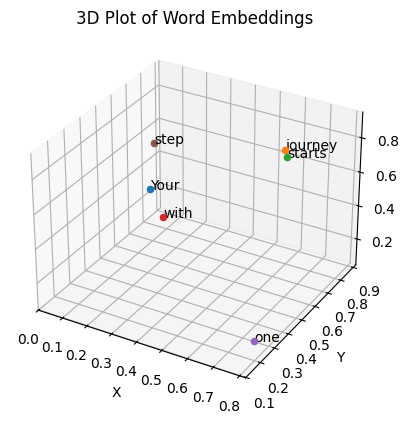

In [215]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

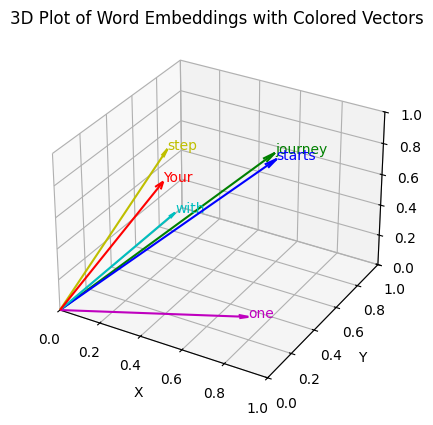

In [216]:
# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()

In [217]:
query = inputs[2] #starts
attn_scores_3 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
  print(i, x_i)
  attn_scores_3[i] = torch.dot(x_i, query)

print(attn_scores_3)

0 tensor([0.4300, 0.1500, 0.8900])
1 tensor([0.5500, 0.8700, 0.6600])
2 tensor([0.5700, 0.8500, 0.6400])
3 tensor([0.2200, 0.5800, 0.3300])
4 tensor([0.7700, 0.2500, 0.1000])
5 tensor([0.0500, 0.8000, 0.5500])
tensor([0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605])


In [218]:
atten_weights_tmp = attn_scores_3/ attn_scores_3.sum()

print(atten_weights_tmp)

tensor([0.1454, 0.2277, 0.2248, 0.1280, 0.1104, 0.1637])


In [219]:
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)
attn_weights_3_naive = softmax_naive(attn_scores_3)
print(attn_weights_3_naive)

tensor([0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565])


In [220]:
attn_weights_3 = torch.softmax(attn_scores_3, dim=0)
print(attn_weights_3)

tensor([0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565])


In [221]:
# Context Vector

In [222]:
query = inputs[2] # 3 rd word - starts

context_vector_3 = torch.zeros(query.shape)

for i, x_i in enumerate(inputs):
  context_vector_3 += attn_weights_3[i]*x_i

print(context_vector_3)

tensor([0.4431, 0.6496, 0.5671])


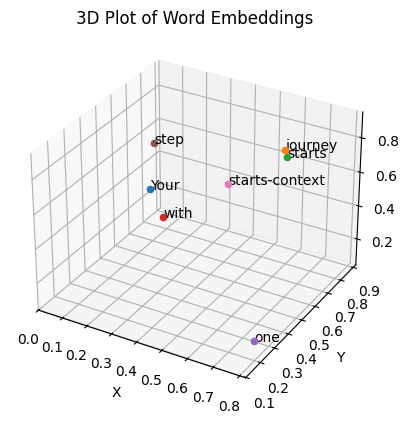

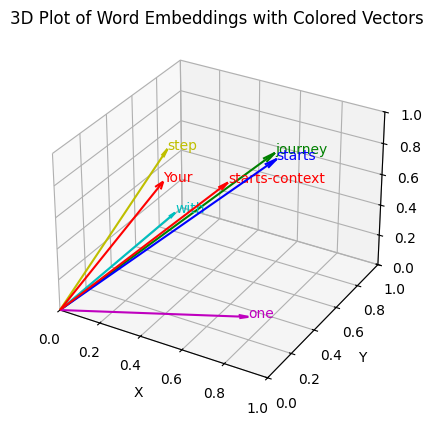

In [223]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55], # step     (x^6)
   [0.4431, 0.6496, 0.5671]]
)

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step', 'starts-context']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y', 'r']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()

In [224]:
attention_scores = torch.empty(6,6)

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55], # step     (x^6)
])

for i, x_i in enumerate(inputs):
  for j, x_j in enumerate(inputs):
    attention_scores[i, j] = torch.dot(x_i, x_j)

print(attention_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [225]:
attn_scores = inputs @ inputs.T
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [226]:
attn_weights = torch.softmax(attn_scores, dim=-1)
print(attn_weights)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


In [227]:
row_2_sum = sum([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
print("Row 2 sum:", row_2_sum)
print("All row sums:", attn_weights.sum(dim=-1))

Row 2 sum: 1.0
All row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [228]:
all_context_vecs = attn_weights @ inputs
print(all_context_vecs)

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


Explantion_link: https://claude.ai/share/f0a18f0a-562c-45e5-b15c-7082888847e2

## IMPLEMENTING SELF ATTENTION WITH TRAINABLE WEIGHTS


In [229]:
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

In [230]:
x_2 = inputs[1]
print(inputs.shape)

torch.Size([6, 3])


In [231]:
d_in = inputs.shape[1]
d_out = 2

In [232]:
torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

In [233]:
W_query

Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]])

In [234]:
W_key

Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]])

<div class="alert alert-block alert-info">
    
Note that we are setting requires_grad=False to reduce clutter in the outputs for
illustration purposes.

If we were to use the weight matrices for model training, we
would set requires_grad=True to update these matrices during model training.

</div>

In [235]:
query_2 = x_2 @ W_query
key_2 = x_2 @ W_key
value_2 = x_2 @ W_value
print(query_2)

tensor([0.4306, 1.4551])


In [236]:
keys = inputs @ W_key
queries = inputs @ W_query
values = inputs @ W_value
print("Shapes of keys and values")
print(keys.shape)
print(values.shape)

Shapes of keys and values
torch.Size([6, 2])
torch.Size([6, 2])


In [237]:
keys_2 = keys[1]
attens_score_22 = query_2.dot(keys_2)
print(attens_score_22)

tensor(1.8524)


In [238]:
attn_scores_2 = query_2 @ keys.T
print(attn_scores_2)

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


In [239]:
attn_scores = queries @ keys.T
print(attn_scores)

tensor([[0.9231, 1.3545, 1.3241, 0.7910, 0.4032, 1.1330],
        [1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
        [1.2544, 1.8284, 1.7877, 1.0654, 0.5508, 1.5238],
        [0.6973, 1.0167, 0.9941, 0.5925, 0.3061, 0.8475],
        [0.6114, 0.8819, 0.8626, 0.5121, 0.2707, 0.7307],
        [0.8995, 1.3165, 1.2871, 0.7682, 0.3937, 1.0996]])


In [240]:
d_k = keys.shape[-1]
attn_weights = torch.softmax(attn_scores/ d_k**0.5, dim=-1)
print(d_k)
print(attn_weights)

2
tensor([[0.1551, 0.2104, 0.2059, 0.1413, 0.1074, 0.1799],
        [0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820],
        [0.1503, 0.2256, 0.2192, 0.1315, 0.0914, 0.1819],
        [0.1591, 0.1994, 0.1962, 0.1477, 0.1206, 0.1769],
        [0.1610, 0.1949, 0.1923, 0.1501, 0.1265, 0.1752],
        [0.1557, 0.2092, 0.2048, 0.1419, 0.1089, 0.1794]])


In [241]:
context_vects = attn_weights @ values
print(context_vects)

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]])


In [242]:
import torch.nn as nn

class SelfAttention_v1(nn.Module):

    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key   = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = x @ self.W_key
        queries = x @ self.W_query
        values = x @ self.W_value

        attn_scores = queries @ keys.T # omega
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1
        )

        context_vec = attn_weights @ values
        return context_vec

In [243]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
print(sa_v1(inputs))

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)


In [244]:
print(sa_v1)

SelfAttention_v1()


In [245]:
class SelfAttention_v2(nn.Module):
   def __init__(self, d_in, d_out, qkv_bias=False):
       super().__init__()
       self.d_out = d_out
       self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
       self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
       self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
   def forward(self, x):
       keys = self.W_key(x)
       queries = self.W_query(x)
       values = self.W_value(x)
       attn_scores = queries @ keys.T
       attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
       context_vec = attn_weights @ values
       return context_vec

In [248]:
torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)


In [250]:
print(sa_v2.W_key)


Linear(in_features=3, out_features=2, bias=False)


In [252]:
sa_v1

SelfAttention_v1()

In [256]:
sa_v1.W_key

Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]], requires_grad=True)

In [263]:
x = sa_v2.W_key.weight
print(x.T)

tensor([[ 0.4058,  0.2134],
        [-0.4704, -0.2601],
        [ 0.2368, -0.5105]], grad_fn=<PermuteBackward0>)


In [265]:
sa_v1.W_query = nn.Parameter(sa_v2.W_query.weight.T)
sa_v1.W_key   = nn.Parameter(sa_v2.W_key.weight.T)
sa_v1.W_value = nn.Parameter(sa_v2.W_value.weight.T)

In [266]:
print(torch.allclose(sa_v1(inputs), sa_v2(inputs)))   # True

True


## HIDING FUTURE WORDS WITH CAUSAL ATTENTION

In [267]:
queries = sa_v2.W_query(inputs)
keys = sa_v2.W_key(inputs)
values = sa_v2.W_value(inputs)

attn_scores = queries @ keys.T

In [268]:
attn_weights = torch.softmax(
    attn_scores / keys.shape[-1]**0.5, dim=-1
)
attn_weights

tensor([[0.1921, 0.1646, 0.1652, 0.1550, 0.1721, 0.1510],
        [0.2041, 0.1659, 0.1662, 0.1496, 0.1665, 0.1477],
        [0.2036, 0.1659, 0.1662, 0.1498, 0.1664, 0.1480],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.1661, 0.1564],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.1585],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)

In [269]:
attn_scores.shape

torch.Size([6, 6])

In [270]:
context_length = attn_scores.shape[0]
mask_simple = torch.tril(torch.ones(context_length, context_length))
mask_simple

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])

In [271]:
masked_simple = attn_weights * mask_simple

In [272]:
masked_simple

tensor([[0.1921, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2041, 0.1659, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2036, 0.1659, 0.1662, 0.0000, 0.0000, 0.0000],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.0000, 0.0000],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<MulBackward0>)

In [273]:
row_sums = masked_simple.sum(dim=1, keepdim=True)
masked_simple_norm = masked_simple / row_sums
print(masked_simple_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<DivBackward0>)
